# NB3_Case_Study_100_Percent_LITE — executed English adaptation

Source: supplied Session5 notebook by Dr. Loveleen Gaur. Original SHA256: `a875bf18e78d01384c58e774edbe6e63980593a6f63584797ab03421ac54585e`.

Public teaching data only. NB3's paper is invented by the instructor for teaching; no invented paper is presented as real literature. Code comments and bilingual labels are rendered in English; computational settings are retained. The optional GPU demo may be skipped if unavailable.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')


## Original code cell 1


In [2]:
import platform, warnings, numpy as np, pandas as pd, sklearn
warnings.filterwarnings('ignore')
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__)
X, y = load_breast_cancer(return_X_y=True)
print('Patients', X.shape[0], '| Features', X.shape[1], '| Malignant', (y == 0).sum(), '| Benign', (y == 1).sum())


Python 3.12.14 | scikit-learn 1.6.1
Patients 569 | Features 30 | Malignant 212 | Benign 357


## Original code cell 3


In [3]:
def paper_pipeline(seed):
    rng = np.random.default_rng(seed)
    minority = np.where(y == 0)[0]
    extra = rng.choice(minority, (y == 1).sum() - len(minority), replace=True)
    Xo, yo = (np.vstack([X, X[extra]]), np.concatenate([y, y[extra]]))
    Xo = StandardScaler().fit_transform(Xo)
    Xo = SelectKBest(f_classif, k=10).fit_transform(Xo, yo)
    Xtr, Xte, ytr, yte = train_test_split(Xo, yo, test_size=0.2, random_state=seed)
    m = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=seed).fit(Xtr, ytr)
    return accuracy_score(yte, m.predict(Xte))
print(f'Step 2{paper_pipeline(12):.1%}')


Step 2100.0%


## Original code cell 5


In [4]:
res = pd.Series({s: paper_pipeline(s) for s in range(20)})
print(res.round(3).to_string())
print(f'\nIs seed 12 the best?{res.idxmax() == 12}')
print(f'Average{res.mean():.1%}   Worst{res.min():.1%}')


0     0.972
1     0.965
2     0.951
3     0.972
4     0.979
5     0.972
6     0.979
7     0.979
8     0.958
9     0.979
10    0.979
11    0.965
12    1.000
13    0.951
14    0.944
15    0.937
16    0.979
17    0.965
18    0.972
19    0.972

Is seed 12 the best?True
Average96.9%   Worst93.7%


## Original code cell 6


In [5]:
rng = np.random.default_rng(12)
minority = np.where(y == 0)[0]
extra = rng.choice(minority, (y == 1).sum() - len(minority), replace=True)
patient_id = np.concatenate([np.arange(len(y)), extra])
tr_idx, te_idx = train_test_split(np.arange(len(patient_id)), test_size=0.2, random_state=12)
shared = set(patient_id[tr_idx]) & set(patient_id[te_idx])
dup = np.array([p in shared for p in patient_id[te_idx]])
print(f'Test rows{len(te_idx)}')
print(f'Test rows whose patient is ALSO in training{dup.sum()} ({dup.mean():.0%})')


Test rows143
Test rows whose patient is ALSO in training41 (29%)


## Original code cell 8


In [6]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=2026)
models = {"Dumb model: always guess 'benign'": DummyClassifier(strategy='most_frequent'), 'Simple model: logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), 'DeepOnco-MLP, done right': make_pipeline(StandardScaler(), SelectKBest(f_classif, k=10), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=0))}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv)
    rows.append({'Model': name, 'Mean': s.mean(), 'SD': s.std(ddof=1), 'Tests': len(s)})
report = pd.DataFrame(rows).set_index('Model')
print(report.round(3).to_string())


                                    Mean     SD  Tests
Model                                                 
Dumb model: always guess 'benign'  0.627  0.004     50
Simple model: logistic regression  0.978  0.014     50
DeepOnco-MLP, done right           0.960  0.016     50


## Original code cell 9


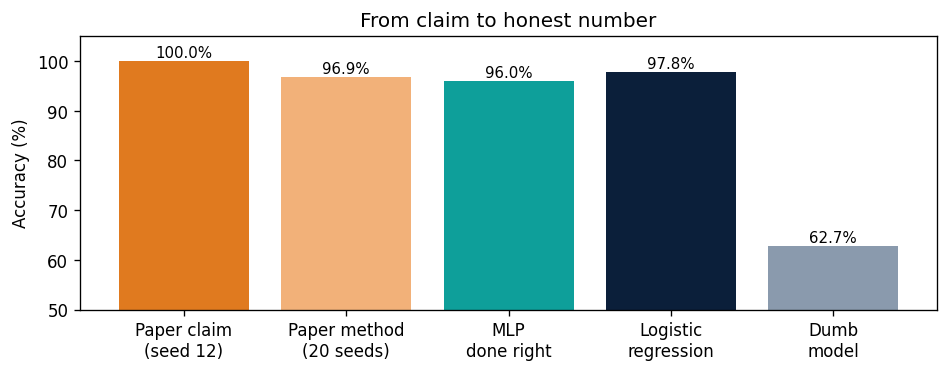

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ['Paper claim\n(seed 12)', 'Paper method\n(20 seeds)', 'MLP\ndone right', 'Logistic\nregression', 'Dumb\nmodel']
vals = [res[12], res.mean(), report.iloc[2, 0], report.iloc[1, 0], report.iloc[0, 0]]
cols = ['#E07A1F', '#F2B179', '#0E9F9A', '#0B1F3A', '#8A9AAD']
ax.bar(labels, np.array(vals) * 100, color=cols)
for i, v in enumerate(vals):
    ax.text(i, v * 100 + 0.8, f'{v:.1%}', ha='center', fontsize=9)
ax.set_ylim(50, 105)
ax.set_ylabel('Accuracy (%)')
ax.set_title('From claim to honest number')
plt.tight_layout()
plt.show()


## Original code cell 11


In [8]:
lr = report.iloc[1]
mlp = report.iloc[2]
print('REPRODUCTION REPORT')
print('-' * 60)
print(f'Same number again?{res[12]:.1%}')
print(f'Is the claim valid?')
print(f'Problems')
print(f'Honest MLP{mlp.iloc[0]:.1%} ± {mlp.iloc[1]:.1%}')
print(f'Simple model{lr.iloc[0]:.1%} ± {lr.iloc[1]:.1%}')
print(f'Environment{platform.python_version()}, scikit-learn {sklearn.__version__}')
print('-' * 60)
print('Reproducible, but not valid.')


REPRODUCTION REPORT
------------------------------------------------------------
Same number again?100.0%
Is the claim valid?
Problems
Honest MLP96.0% ± 1.6%
Simple model97.8% ± 1.4%
Environment3.12.14, scikit-learn 1.6.1
------------------------------------------------------------
Reproducible, but not valid.


In [9]:
from pathlib import Path
import json
repeat_seed12=paper_pipeline(12)
Path('results.json').write_text(json.dumps({'seed12_accuracy':float(res[12]),'seed12_repeated_accuracy':float(repeat_seed12),'same_seed_repeat_identical':bool(repeat_seed12==res[12]),'twenty_seed_mean':float(res.mean()),'test_rows_with_patient_also_in_train':int(dup.sum()),'test_rows':int(len(te_idx)),'honest_comparators':report.reset_index().to_dict(orient='records'),'data_origin':'PUBLIC_WISCONSIN_TEACHING_DATA','paper_status':'INVENTED_INSTRUCTOR_EXAMPLE'},indent=2)+'\n',encoding='utf-8')
